# Projet Systèmes de Recommandation — Recommandeur hybride sur Amazon Reviews 2023
**Cours** Systèmes de Recommandation (II3-IA) · **Dataset** Amazon Reviews 2023 (McAuley Lab) · **Auteur** : *(ton nom)*

Ce notebook suit l'énoncé point par point :
1. Choix du domaine et du dataset · 2. Analyse et préparation des données · 3. Approches de base ·
4. Approche hybride · 5. Évaluation expérimentale (+ cold-start) · 6. Démonstration · 7. Utilisation de l'IA générative.

> ⚠️ **Avant de rendre** : relance tout le notebook sur les VRAIES données (`USE_SYNTHETIC = False`), puis complète
> les cellules « À COMPLÉTER » avec TES analyses des résultats obtenus. Rien dans ce modèle n'est un résultat.

In [1]:
import os, sys, subprocess
sys.path.insert(0, os.path.abspath(".."))          # racine du projet

USE_SYNTHETIC = False   # True UNIQUEMENT pour tester que le code tourne (données factices, résultats sans valeur)
if USE_SYNTHETIC:
    os.environ["RS_CATEGORIES"] = "Synth_A,Synth_B,Synth_C"; os.environ["RS_USERS_PER_CAT"] = "400"
    subprocess.run([sys.executable, "../scripts/make_synthetic.py"], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import config as C
from src import data as D, models as M, evaluation as E, pipeline as P, metrics as MT, explain as X
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
print("Catégories :", C.CATEGORIES, "| utilisateurs/catégorie :", C.N_USERS_PER_CAT, "| seed :", C.SEED)

Catégories : ['Video_Games', 'Software', 'Musical_Instruments'] | utilisateurs/catégorie : 2000 | seed : 42


## 1. Choix du domaine et du dataset
**Domaine** : e-commerce (produits Amazon). **Dataset** : *Amazon Reviews 2023* (McAuley Lab, UCSD), public et gratuit :
https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023 · site : https://amazon-reviews-2023.github.io/

* **Interactions utilisateur–item** : avis (utilisateur, produit, note, horodatage).
* **Descriptions des items** : métadonnées (titre, catégories, caractéristiques, description, prix, note moyenne, marque).
* **Choix de conception** : 3 catégories (*Video_Games*, *Software*, *Musical_Instruments*) et **même nombre d'utilisateurs par catégorie**
  → catalogue équilibré entre catégories. Une interaction est dite *positive* si note ≥ 4 (feedback implicite, chap. 6).
  Les notes Amazon sont très biaisées vers 5 étoiles : on ne peut pas « équilibrer » les notes sans fausser les données, d'où ce choix.

**Téléchargement** (une seule fois, ~quelques centaines de Mo, sans compte) :

In [2]:
# Décommente pour télécharger (équivalent à : python scripts/download_data.py)
# subprocess.run([sys.executable, "../scripts/download_data.py"], check=True)
print(sorted(p.name for p in C.DATA_RAW.glob("*") if p.name != ".gitkeep"))

['Musical_Instruments.csv', 'Software.csv', 'Video_Games.csv', 'meta_Musical_Instruments.jsonl', 'meta_Software.jsonl', 'meta_Video_Games.jsonl']


## 2. Analyse et préparation des données

Données brutes : 2,603,262 interactions · 290,319 utilisateurs · 67,790 items


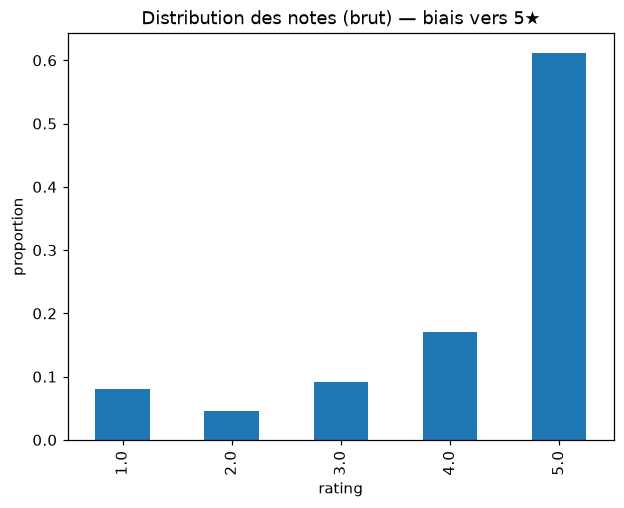

In [3]:
raw = D.load_interactions()
print(f"Données brutes : {len(raw):,} interactions · {raw.user_id.nunique():,} utilisateurs · {raw.item_id.nunique():,} items")
raw["rating"].value_counts(normalize=True).sort_index().plot.bar(title="Distribution des notes (brut) — biais vers 5★")
plt.ylabel("proportion"); plt.show()

In [4]:
ds = D.build_dataset()   # positifs (note>=4) -> k-core -> échantillon équilibré par catégorie -> métadonnées
stats = D.basic_stats(ds)
pd.Series(stats).to_frame("valeur")

Brut : 2,603,262 interactions, 290,319 utilisateurs, 67,790 items
Positifs (note>=4) + k-core : 1,769,250 interactions, 204,434 utilisateurs
Final : 16,440 interactions, 2,140 utilisateurs, 2,276 items


,valeur
utilisateurs,2140.000000
items,2276.000000
interactions,16440.000000
sparsité,0.996625
interactions/utilisateur (médiane),6.000000
interactions/item (médiane),4.000000
part des interactions captée par le top 1% des items,0.004988


Taux de remplissage de la matrice = 0.3375% | sparsité = 99.6625%


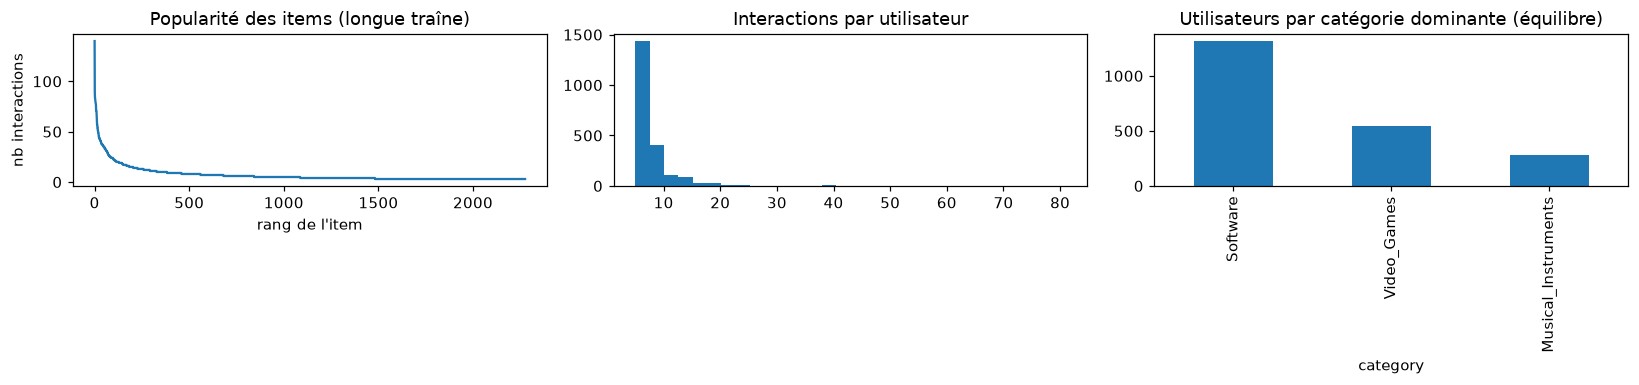

Interactions par catégorie :
category
Musical_Instruments     1984
Software               10069
Video_Games             4387
dtype: int64
Items par catégorie :
category
Software               1076
Video_Games             816
Musical_Instruments     384
Name: count, dtype: int64


In [5]:
print("Taux de remplissage de la matrice =", f"{1 - stats['sparsité']:.4%}", "| sparsité =", f"{stats['sparsité']:.4%}")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pop = ds.inter["i"].value_counts().values
ax[0].plot(pop); ax[0].set_title("Popularité des items (longue traîne)"); ax[0].set_xlabel("rang de l'item"); ax[0].set_ylabel("nb interactions")
ax[1].hist(ds.inter.groupby("u").size(), bins=30); ax[1].set_title("Interactions par utilisateur")
ds.user_main_cat.value_counts().plot.bar(ax=ax[2], title="Utilisateurs par catégorie dominante (équilibre)")
plt.tight_layout(); plt.show()
print("Interactions par catégorie :"); print(ds.inter.groupby("category").size())
print("Items par catégorie :");      print(ds.items["category"].value_counts())

### Découpage train / validation / test
**Leave-one-out temporel** (chap. 6) : pour chaque utilisateur, la **dernière** interaction → *test*, l'**avant-dernière** → *validation*,
le reste → *apprentissage*. On « prédit le futur à partir du passé » (le plus proche de la réalité).
Évaluation par **classement complet du catalogue** (on exclut seulement l'historique), sans échantillonnage de négatifs.
> Avec un seul item pertinent par utilisateur : **Recall@K = HR@K** et **Precision@K = HR@K / K**.

In [6]:
sp_ = E.Split(ds)
print(f"train={len(sp_.train):,}  val={len(sp_.val):,}  test={len(sp_.test):,}  | utilisateurs={ds.n_users:,}")

train=12,160  val=2,140  test=2,140  | utilisateurs=2,140


## 3. Approches de base
| Modèle | Chapitre | Principe |
|---|---|---|
| Popularité | 1 | baseline non personnalisée : `log(1 + nb d'interactions)` |
| CF item-item | 2 | similarité cosinus entre items, 50 voisins/item, score = somme des similarités avec l'historique |
| CF SVD (PureSVD) | 2 | factorisation de la matrice binaire, utilisateur projeté dans l'espace latent (*fold-in*) |
| Contenu TF-IDF | 3 | TF-IDF (uni+bigrammes) sur titre+catégories+caractéristiques+description ; profil = moyenne des items vus ; cosinus |

Tous scorent à partir de l'**historique** (et non d'un identifiant) : on peut donc servir des utilisateurs presque nouveaux sans réentraîner.

In [7]:
models = M.fit_all(sp_.R_train, sp_.texts)
X_div = models["content"].X
print({k: type(v).__name__ for k, v in models.items()})

{'pop': 'Popularity', 'knn': 'ItemKNN', 'svd': 'SVDModel', 'content': 'ContentTFIDF'}


In [8]:
# Évaluation de chaque approche seule (historique = train + validation, cible = dernier item)
base = E.evaluate_all(models, {}, sp_.R_trainval, sp_.test_target, sp_.pop, sp_.item_frac, X_div)
base.round(4)

,Precision@10,Recall@10,HR@10,NDCG@10,MRR,n,Couverture,Nouveauté,Diversité
Popularité,0.0054,0.0542,0.0542,0.0251,0.0164,2140.0,0.0070,5.1844,0.9707
CF item-item,0.0087,0.0874,0.0874,0.0438,0.0308,2140.0,0.9473,9.0523,0.9502
CF SVD,0.0085,0.0850,0.0850,0.0473,0.0358,2140.0,0.2983,7.0212,0.9551
Contenu TF-IDF,0.0110,0.1098,0.1098,0.0567,0.0407,2140.0,0.8616,9.2719,0.8421


## 4. Approche hybride : stratégie et justification
Stratégie retenue (chapitre 5) : **pondérée + commutation (*switching*)**, architecture parallèle :

1. **Pondérée** : `score = Σ w_k · score_k` où chaque score est normalisé par son maximum (par utilisateur) pour être comparable.
   Poids choisis par **recherche en grille** (pas 0,1, somme = 1) maximisant NDCG@10 sur la **validation**.
2. **Commutation côté utilisateur** : un jeu de poids « froid » (historique < 5 interactions) et un jeu « chaud ».
   Les poids froids sont réglés sur 30 % d'utilisateurs dont l'historique est tronqué à 2 interactions
   (*split* disjoint de celui utilisé pour tester).
3. **Commutation côté item** : un item **sans aucune interaction** est scoré par le contenu seul (le CF ne peut pas le voir).

*Pourquoi ce choix ?* Le CF est le plus précis quand l'historique existe, mais il échoue sur les nouveaux utilisateurs/items ;
le contenu et la popularité couvrent ces cas. La pondération est simple, interprétable et permet des explications.

In [9]:
res = P.run_experiments(ds, verbose=True)     # tuning + toutes les expériences + sauvegarde des artefacts
w_warm, w_cold = res["w_warm"], res["w_cold"]
print("\nPoids chauds :", w_warm, "\nPoids froids :", w_cold)

Poids optimaux (utilisateurs 'chauds') : {'knn': 0.2, 'svd': 0.1, 'content': 0.4, 'pop': 0.3}
Poids optimaux (utilisateurs 'froids') : {'knn': 0.1, 'svd': 0.0, 'content': 0.7, 'pop': 0.2}
                   Precision@10  Recall@10   HR@10  NDCG@10     MRR       n  Couverture  Nouveauté  Diversité
Popularité               0.0054     0.0542  0.0542   0.0251  0.0164  2140.0      0.0070     5.1844     0.9707
CF item-item             0.0087     0.0874  0.0874   0.0438  0.0308  2140.0      0.9473     9.0523     0.9502
CF SVD                   0.0085     0.0850  0.0850   0.0473  0.0358  2140.0      0.2983     7.0212     0.9551
Contenu TF-IDF           0.0110     0.1098  0.1098   0.0567  0.0407  2140.0      0.8616     9.2719     0.8421
Hybride pondéré          0.0140     0.1397  0.1397   0.0780  0.0592  2140.0      0.6670     7.1818     0.9088
Hybride switching        0.0144     0.1444  0.1444   0.0790  0.0592  2140.0      0.7465     8.3334     0.8896

Poids chauds : {'knn': 0.2, 'svd': 0.1, '

In [10]:
print("Top 10 des combinaisons de poids (utilisateurs chauds, validation) :")
res["tab_warm"].head(10).round(4)

Top 10 des combinaisons de poids (utilisateurs chauds, validation) :


,knn,svd,content,pop,NDCG@10,HR@10
0,0.2,0.1,0.4,0.3,0.0928,0.1660
1,0.2,0.2,0.3,0.3,0.0923,0.1640
2,0.2,0.2,0.4,0.2,0.0911,0.1605
3,0.1,0.2,0.4,0.3,0.0901,0.1595
4,0.2,0.1,0.3,0.4,0.0900,0.1565
5,0.3,0.1,0.3,0.3,0.0893,0.1580
6,0.1,0.3,0.4,0.2,0.0874,0.1575
7,0.2,0.3,0.3,0.2,0.0873,0.1560
8,0.3,0.2,0.3,0.2,0.0871,0.1515
9,0.2,0.3,0.2,0.3,0.0870,0.1535


## 5. Évaluation expérimentale
Comparaison de l'hybride à chaque approche seule et à la baseline de popularité.
Métriques de précision : **Precision@10, Recall@10, HR@10, NDCG@10, MRR** · Au-delà de la précision : **couverture, diversité (1 − ILS), nouveauté**.

In [11]:
main = res["main"]
main.round(4)

,Precision@10,Recall@10,HR@10,NDCG@10,MRR,n,Couverture,Nouveauté,Diversité
Popularité,0.0054,0.0542,0.0542,0.0251,0.0164,2140.0,0.0070,5.1844,0.9707
CF item-item,0.0087,0.0874,0.0874,0.0438,0.0308,2140.0,0.9473,9.0523,0.9502
CF SVD,0.0085,0.0850,0.0850,0.0473,0.0358,2140.0,0.2983,7.0212,0.9551
Contenu TF-IDF,0.0110,0.1098,0.1098,0.0567,0.0407,2140.0,0.8616,9.2719,0.8421
Hybride pondéré,0.0140,0.1397,0.1397,0.0780,0.0592,2140.0,0.6670,7.1818,0.9088
Hybride switching,0.0144,0.1444,0.1444,0.0790,0.0592,2140.0,0.7465,8.3334,0.8896


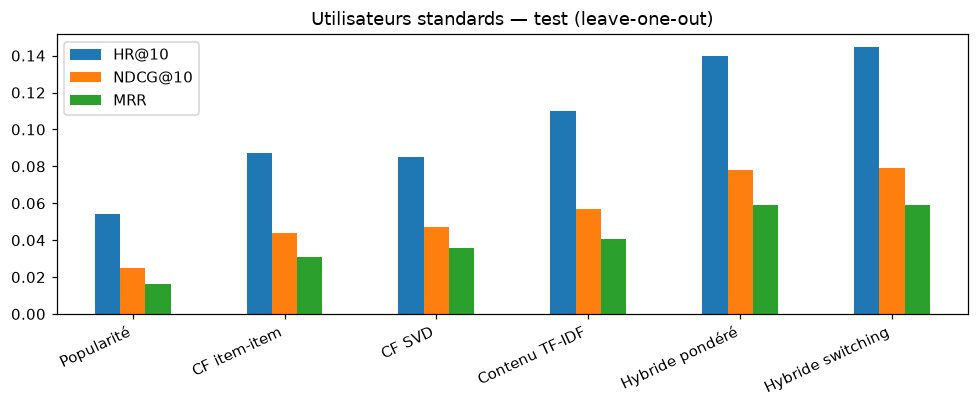

,Couverture,Diversité,Nouveauté
Popularité,0.007,0.971,5.184
CF item-item,0.947,0.950,9.052
CF SVD,0.298,0.955,7.021
Contenu TF-IDF,0.862,0.842,9.272
Hybride pondéré,0.667,0.909,7.182
Hybride switching,0.746,0.890,8.333


In [12]:
ax = main[["HR@10", "NDCG@10", "MRR"]].plot.bar(figsize=(9, 3.8), title="Utilisateurs standards — test (leave-one-out)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
main[["Couverture", "Diversité", "Nouveauté"]].round(3)

### 5.1 Cold-start utilisateurs
30 % des utilisateurs voient leur historique d'apprentissage **tronqué** à 1, 2 ou 3 interactions ; tous les modèles sont **réentraînés**
sur ces données tronquées. L'évaluation porte sur la moitié de ces utilisateurs qui n'a **pas** servi au réglage des poids froids.

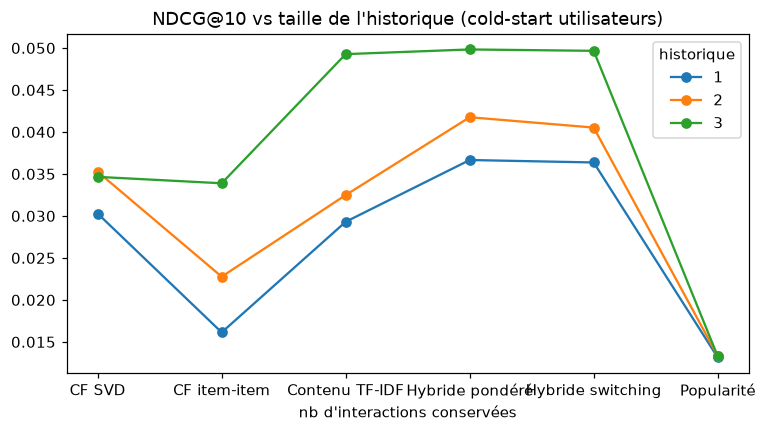

historique,1,2,3
modèle,,,
CF SVD,0.0498,0.0685,0.0498
CF item-item,0.0374,0.0467,0.0530
Contenu TF-IDF,0.0498,0.0717,0.1059
Hybride pondéré,0.0717,0.0872,0.0872
Hybride switching,0.0685,0.0841,0.0997
Popularité,0.0249,0.0249,0.0249


In [13]:
rows = []
for n, t in res["cold_users"].items():
    for model, r in t.iterrows():
        rows.append({"historique": n, "modèle": model, "HR@10": r["HR@10"], "NDCG@10": r["NDCG@10"], "n": int(r["n"])})
cold = pd.DataFrame(rows)
piv = cold.pivot(index="modèle", columns="historique", values="NDCG@10")
piv.plot(marker="o", figsize=(8, 4), title="NDCG@10 vs taille de l'historique (cold-start utilisateurs)"); plt.xlabel("nb d'interactions conservées"); plt.show()
cold.pivot(index="modèle", columns="historique", values="HR@10").round(4)

### 5.2 Cold-start items (nouveaux produits)
5 % des items sont retirés de l'apprentissage (ils n'ont **aucune** interaction connue) ; on évalue les utilisateurs dont l'item de test est l'un d'eux.
Seules les approches capables d'utiliser le contenu peuvent les retrouver.

In [14]:
print("Utilisateurs évalués :", res["cold_items_n_users"])
res["cold_items"].round(4)

Utilisateurs évalués : 123


,Precision@10,Recall@10,HR@10,NDCG@10,MRR,n,Couverture,Nouveauté,Diversité
Popularité,0.0000,0.0000,0.0000,0.0000,0.0000,123.0,0.0062,5.1861,0.9707
CF item-item,0.0000,0.0000,0.0000,0.0000,0.0000,123.0,0.3185,9.0215,0.9452
CF SVD,0.0000,0.0000,0.0000,0.0000,0.0000,123.0,0.1406,6.9708,0.9558
Contenu TF-IDF,0.0146,0.1463,0.1463,0.0757,0.0538,123.0,0.3076,10.4219,0.8240
Hybride pondéré,0.0000,0.0000,0.0000,0.0000,0.0000,123.0,0.2069,7.2365,0.9059
Hybride switching,0.0179,0.1789,0.1789,0.1087,0.0868,123.0,0.2425,10.0956,0.8785


### 5.3 Analyse des résultats — **À COMPLÉTER avec tes résultats réels**
* Quel modèle est le meilleur en précision (HR/NDCG) ? L'hybride bat-il chaque approche seule ? De combien ? (attention : avec peu d'utilisateurs de test, l'écart peut être dans le bruit ; pense à un intervalle de confiance ou à plusieurs *seeds*).
* Compromis précision / couverture / diversité / nouveauté observé ?
* Quel modèle gère le mieux le cold-start utilisateur ? item ? Le *switching* aide-t-il ?
* Limites : un seul jeu de données, un seul item cible par utilisateur, biais de l'évaluation hors ligne (chap. 6).

## 6. Démonstration
Interface Gradio : `python app.py` → http://127.0.0.1:7860 (les artefacts `artifacts/bundle.pkl` ont été écrits à l'étape 4).
Elle propose : utilisateur existant (avec simulation de cold-start), nouvel utilisateur par mots-clés, filtres par contraintes (prix, note, catégorie)
avec relaxation automatique, et **une explication par recommandation**.
Aperçu des explications directement dans le notebook :

In [15]:
import scipy.sparse as sp
hyb = M.HybridSwitch(models, w_cold, w_warm)
items = ds.items
u = int(np.random.default_rng(1).integers(ds.n_users))
hist = sp_.R_trainval[u].indices
H = sp.csr_matrix(sp_.R_trainval[u])
s = hyb.score(H)[0]; s[hist] = -np.inf
top = np.argsort(-s)[:5]
w = hyb.weights_for(len(hist)); comp = M.HybridWeighted(models, w).components(H)
print(f"Utilisateur {u} — {len(hist)} interactions. Derniers achats :")
for i in hist[-3:]: print("  •", items.loc[i, "title"][:80])
print("\nRecommandations :")
for r, i in enumerate(top, 1):
    print(f"{r}. {items.loc[i, 'title'][:80]}\n   → {X.explain(i, hist, models, w, items, {k: v[0, i] for k, v in comp.items()})}")

Utilisateur 1012 — 18 interactions. Derniers achats :
  • The Secret Order 5: The Buried Kingdom
  • League of Light: The Gatherer Collector's Edition
  • Bridge to Another World: Alice in Shadowland Collector's Edition

Recommandations :
1. Big Fish Games App
   → Mots-clés en commun avec votre profil : big fish, fish, fish games, collector ; article populaire auprès des clients. [Contributions : contenu 67%, popularité 27%, collaboratif item-item 6%]
2. Enigmatis: The Ghosts of Maple Creek Free
   → Les acheteurs de « bridge to another world: alice in shadowland collector's edi » ont aussi aimé cet article (sim. 0.33) ; mots-clés en commun avec votre profil : big fish, fish games, fish, big ; article populaire auprès des clients. [Contributions : contenu 42%, popularité 39%, collaboratif item-item 13%, collaboratif SVD 6%]
3. Candy Crush Saga
   → Mots-clés en commun avec votre profil : puzzle adventure, puzzles, puzzle, game ; article populaire auprès des clients. [Contributions : p

## 7. Utilisation de l'IA générative
> **À COMPLÉTER** (l'énoncé exige la transparence totale). Joindre l'export **complet et sans coupure** de TOUTES les conversations avec l'assistant (dossier `ia_historique/`).

| Partie du code | Générée par l'IA ? | Modifiée / écrite à la main ? | Détails |
|---|---|---|---|
| `src/data.py` | | | |
| `src/models.py` | | | |
| `src/evaluation.py` | | | |
| `src/metrics.py` | | | |
| `app.py` | | | |

**Erreurs de l'IA repérées et corrigées** : *(liste)*

**Choix techniques faits par moi plutôt que par l'IA** : *(liste : seuil de positivité, K-core, stratégie hybride, grille de poids, protocole d'évaluation…)*